# Kikuchi COM asymmetry — audit of three reported problems

Re-derives everything from the original `.npz` simulations. Three claims under test:

1. **The COM calculation is wrong** — it takes each box's centroid and compares their
   midpoint to the centre, instead of masking everything but the two boxes and taking
   the centroid of what is left.
2. **The centre point is off by a pixel.**
3. **The wrong polarisation direction was simulated** — no asymmetry at zero tilt along
   the measured direction, but there is one along the perpendicular direction.

Verdicts: **1 confirmed**, **2 confirmed but in the box mirror, not in `center_y`**,
**3 confirmed for PTO only** — BTO and boracite are correctly oriented.

All helpers live in `kikuchi_com.py` so the notebook and any re-run of the simulations
share one definition.

In [1]:
import os, json
import numpy as np
import matplotlib.pyplot as plt

import kikuchi_com as kc
from kikuchi_com import (N, FULL_BOX, THIRD_BOX, mirror_box, old_mirror_box,
                         masked_com, midpoint_com, stream_patterns, zone_axis_ratio)

kc._self_check()

CACHE = "cache"
os.makedirs(CACHE, exist_ok=True)

def cached(name, fn):
    """Run fn() once; the sweeps read 10 GB per material so never redo them."""
    path = os.path.join(CACHE, name + ".npy")
    if os.path.exists(path):
        return np.load(path, allow_pickle=True)
    out = fn()
    np.save(path, out)
    return out

LONG = {"PTO":      "long_range/PTO_long_range_kikuchi_asymmetry_data.npz",
        "BTO":      "long_range/BTO_long_range_kikuchi_asymmetry_data.npz",
        "Boracite": "long_range/Boracite_long_range_kikuchi_asymmetry_data.npz"}

def frame(path, k):
    """Frame k without decompressing the whole 10 GB member."""
    import itertools
    return next(itertools.islice(stream_patterns(path), k, k + 1))

def zero_tilt_pattern(path):
    return frame(path, int(np.argmin(abs(tilts(path)))))

def tilts(path):
    import zipfile, io
    zf = zipfile.ZipFile(path)
    name = next(n for n in zf.namelist() if n.startswith("tilt_y_values"))
    with zf.open(name) as h:
        return np.load(io.BytesIO(h.read()))

for nm, b in (("full ", FULL_BOX), ("third", THIRD_BOX)):
    print(f"{nm} box1={b}  published box2={old_mirror_box(b)}  exact mirror={mirror_box(b)}")

kikuchi_com self-check OK
full  box1=(800, 1400, 1988, 2108)  published box2=(2696, 3296, 1988, 2108)  exact mirror=(2697, 3297, 1988, 2108)
third box1=(800, 1000, 1988, 2108)  published box2=(3096, 3296, 1988, 2108)  exact mirror=(3097, 3297, 1988, 2108)


## Claim 2a — where is the pattern centre?

Two independent estimates on the PTO zero-tilt pattern: the direct-beam centroid, and the
mirror-symmetry centre of each marginal profile (the value of $S$ maximising
$\sum_i f(i)f(S-i)$, giving the centre as $S/2$ at half-pixel resolution).

In [2]:
p = zero_tilt_pattern(LONG["PTO"])

iy, ix = np.unravel_index(np.argmax(p), p.shape)
r = 30
sub = p[iy-r:iy+r+1, ix-r:ix+r+1]
yy, xx = np.mgrid[iy-r:iy+r+1, ix-r:ix+r+1]
print(f"brightest pixel           : ({iy}, {ix})")
print(f"direct-beam centroid      : ({(sub*yy).sum()/sub.sum():.3f}, {(sub*xx).sum()/sub.sum():.3f})")

def mirror_centre(f):
    f = f - f.min()
    n = len(f)
    k = int(np.argmax(np.correlate(f, f[::-1], mode="full")))
    best = max(((S, sum(f[i]*f[S-i] for i in range(n) if 0 <= S-i < n))
                for S in range(k-4, k+5)), key=lambda t: t[1])
    return best[0] / 2

print(f"mirror centre, axis-0 prof: {mirror_centre(p.sum(axis=1)):.1f}")
print(f"mirror centre, axis-1 prof: {mirror_centre(p.sum(axis=0)):.1f}")
print(f"\nN/2     = {N/2}      <- what the published code uses")
print(f"(N-1)/2 = {(N-1)/2}")

brightest pixel           : (2048, 2048)
direct-beam centroid      : (2048.004, 2048.640)
mirror centre, axis-0 prof: 2048.0
mirror centre, axis-1 prof: 2048.0

N/2     = 2048.0      <- what the published code uses
(N-1)/2 = 2047.5


`center_y = ny / 2` is **right**. Both estimators land on index 2048.0; `(N-1)/2 = 2047.5`
would be wrong. abTEM returns an fftshifted grid, so for even $N$ the zero-frequency pixel
sits at index $N/2$ exactly.

## Claim 2b — the off-by-one is in the box mirror

`infer_box2_from_box1` maps the half-open slice `[lo, hi)` to `[N-hi, N-lo)`. Reflecting row
$r \mapsto N - r$ sends rows `lo … hi-1` to rows `N-hi+1 … N-lo`, i.e. the half-open slice
`[N+1-hi, N+1-lo)`. Box 2 was one pixel off.

Test it on the **non-polar** array axis, which must be symmetric, so the true answer is 0.

In [3]:
rows = []
for name, path in LONG.items():
    pat = zero_tilt_pattern(path)
    for axis, lbl in ((0, "axis 0"), (1, "axis 1")):
        rows.append((name, lbl,
                     midpoint_com(pat, FULL_BOX, old_mirror_box(FULL_BOX), axis),
                     midpoint_com(pat, FULL_BOX, mirror_box(FULL_BOX), axis)))
    del pat

print(f"{'material':10s} {'axis':7s} {'published mirror':>17s} {'exact mirror':>14s}")
for n_, a_, o_, f_ in rows:
    print(f"{n_:10s} {a_:7s} {o_:>+17.4f} {f_:>+14.4f}")
print("\nThe non-polar axis must read 0. Published mirror is biased by ~-0.51 px everywhere.")

material   axis     published mirror   exact mirror
PTO        axis 0            -0.5763        -0.0651
PTO        axis 1            -0.5789        -0.0700
BTO        axis 0            -0.4753        +0.0176
BTO        axis 1            -0.4618        +0.0444
Boracite   axis 0            -0.3078        +0.2059
Boracite   axis 1            -0.6271        -0.1130

The non-polar axis must read 0. Published mirror is biased by ~-0.51 px everywhere.


## Claim 3 — which array axis carries the polarisation?

abTEM returns the pattern indexed `[kx, ky]`, so array axis 0 is lab *x* even though the
published code calls it "y". Two things must line up with the polar axis: the analysis boxes,
and the tilt.

**Which array axis does the tilt move?** The 9x9 `tilt_x` x `tilt_y` grid answers it directly.

In [4]:
def grid_map():
    g = np.zeros((2, 9, 9))
    for n_, q in enumerate(stream_patterns("grids/kikuchi/PTO_kikuchi_grid.npz")):
        i, j = divmod(n_, 9)
        g[0, i, j] = masked_com(q, FULL_BOX, axis=0)
        g[1, i, j] = masked_com(q, FULL_BOX, axis=1)
    return g

g = cached("pto_grid_map", grid_map)
np.set_printoptions(precision=1, suppress=True, linewidth=200)
print("PTO grid, masked COM on ARRAY AXIS 0   (rows i = tilt_y, cols j = tilt_x)")
print(g[0])
print("\nPTO grid, masked COM on ARRAY AXIS 1")
print(g[1])
print("\naxis 0 varies down i (tilt_y) and is symmetric across j")
print("axis 1 varies across j (tilt_x), is antisymmetric in j, and is ZERO at j=4 (tilt_x=0)")

PTO grid, masked COM on ARRAY AXIS 0   (rows i = tilt_y, cols j = tilt_x)
[[-120.5  -66.9  -68.4 -141.3  -43.6 -141.7  -68.8  -65.7 -120.6]
 [-109.7  -48.2 -164.7  -79.8   -8.1  -79.6 -164.9  -47.7 -110.8]
 [ -32.1  -72.9 -127.5 -152.7  -92.1 -153.1 -127.6  -72.1  -31.7]
 [ -65.1 -133.   -59.1  -44.4  -25.7  -44.8  -58.7 -133.1  -65. ]
 [  19.4   16.7   26.1   49.4   24.6   49.8   26.4   16.6   20.4]
 [  58.6  158.3   38.1   51.4   22.7   51.2   38.   158.2   58.4]
 [  85.4   57.   130.8  128.5    5.2  128.9  131.4   56.5   84.7]
 [ 116.    -8.3  125.6   91.9   58.7   92.6  126.2   -7.6  116.3]
 [  53.7   53.8   66.   107.8    4.9  109.    66.    53.6   54.9]]

PTO grid, masked COM on ARRAY AXIS 1
[[  52.4   65.1   61.7  109.7   -0.2 -110.3  -61.   -64.9  -52. ]
 [   7.2    9.9   88.7  159.7   -0.6 -159.1  -89.   -10.    -7.9]
 [  63.5  134.1  114.3   58.5   -0.1  -58.8 -114.1 -135.2  -64. ]
 [ 155.6   56.    89.7   48.7    0.3  -48.9  -88.7  -56.6 -155.4]
 [  41.5   40.5   54.4   27.9

So `rotate(tilt_y, "y")` moves the pattern along **array axis 0**, which is where the boxes
are. Boxes and tilt agree with each other.

**Where does the polar axis actually sit?** abTEM's antialias aperture is a circle in
*reciprocal* space, so in pixels it is an ellipse with semi-axis ratio
$= \mathrm{extent}_x/\mathrm{extent}_y = c/a$. That reads the crystal orientation straight off
the data, with no intensity assumption at all.

In [5]:
EXPECT = {"PTO  zone [100]": 3.9423/3.8862, "PTO  zone [010]": 3.8862/3.9423,
          "BTO  zone [100]": 4.0230/3.9905, "BTO  zone [010]": 3.9905/4.0230,
          "boracite (square)": 1.0}
for k, v in EXPECT.items():
    print(f"  expected  {k:20s} {v:.5f}")

DATASETS = ["long_range/PTO_long_range_kikuchi_asymmetry_data.npz",
            "short_range/PTO_kikuchi_15_slice_final_asymmetry_data.npz",
            "short_range/1_slice_thickness/PTO_kikuchi_1_clice_final_asymmetry_data.npz",
            "INCOMPLETE_PTO_kikuchi_final_asymmetry_data.npz",
            "grids/kikuchi/PTO_kikuchi_grid.npz",
            "long_range/BTO_long_range_kikuchi_asymmetry_data.npz",
            "short_range/BTO_kikuchi_final_15_slice_asymmetry_data.npz",
            "long_range/Boracite_long_range_kikuchi_asymmetry_data.npz"]

def audit():
    out = {}
    for f in DATASETS:
        n = len(tilts(f))
        k = (n // 2) * n + n // 2 if "grid" in f else n // 2   # grids are n x n
        out[f] = zone_axis_ratio(frame(f, k))
    return np.array([out], dtype=object)

ratios = cached("zone_audit", audit)[0]
print(f"\n{'dataset':62s} {'ratio':>8s}  polar axis")
for f, r in ratios.items():
    print(f"{f[-62:]:62s} {r:>8.5f}  {'axis 1  <-- WRONG' if r < 0.995 else 'axis 0'}")

  expected  PTO  zone [100]      1.01444
  expected  PTO  zone [010]      0.98577
  expected  BTO  zone [100]      1.00814
  expected  BTO  zone [010]      0.99192
  expected  boracite (square)    1.00000

dataset                                                           ratio  polar axis
long_range/PTO_long_range_kikuchi_asymmetry_data.npz            0.98577  axis 1  <-- WRONG
short_range/PTO_kikuchi_15_slice_final_asymmetry_data.npz       1.00831  axis 0
1_slice_thickness/PTO_kikuchi_1_clice_final_asymmetry_data.npz  0.98613  axis 1  <-- WRONG
INCOMPLETE_PTO_kikuchi_final_asymmetry_data.npz                 1.01521  axis 0
grids/kikuchi/PTO_kikuchi_grid.npz                              1.01521  axis 0
long_range/BTO_long_range_kikuchi_asymmetry_data.npz            1.00831  axis 0
short_range/BTO_kikuchi_final_15_slice_asymmetry_data.npz       1.00831  axis 0
long_range/Boracite_long_range_kikuchi_asymmetry_data.npz       1.00000  axis 0


`long_range/PTO...` and `1_slice_thickness/PTO...` measure **0.9858 = PTO's $a/c$**, which is
what `ZONE_AXIS = [0,1,0]` produces. Their polar axis is on array axis 1, while the boxes and
the tilt are both on axis 0 — so for PTO the published sweep measured the non-polar direction
*and* tilted perpendicular to **P**.

Two incidental findings: `short_range/PTO_kikuchi_15_slice_final...` reads 1.0083, which is
BaTiO3's ratio, not PbTiO3's — that file is not PTO. And `INCOMPLETE_PTO_kikuchi_final...` is
correctly oriented and actually complete (41 tilts, no blank frames), despite the name.

## Claim 1 — the metric, and the full sweeps

`masked_com` minus `midpoint_com` is exactly $\frac{c_1-c_2}{2}\cdot\frac{I_1-I_2}{I_1+I_2}$,
about $-948\,\mathrm{px}$ times the normalised intensity imbalance. The midpoint cancels that
term, which is the signal.

In [6]:
BOXES = {"full": FULL_BOX, "third": THIRD_BOX}

def sweep(path):
    """One pass over the 10 GB file; both box sizes, all four metrics each."""
    rows = []
    for q in stream_patterns(path):
        r = []
        for b in BOXES.values():
            r += [midpoint_com(q, b, old_mirror_box(b), 0),   # published
                  midpoint_com(q, b, mirror_box(b), 0),       # mirror fixed
                  masked_com(q, b, mirror_box(b), 0),         # fully fixed, ax0
                  masked_com(q, b, mirror_box(b), 1)]         # fully fixed, ax1
        rows.append(r)
    return np.array(rows)   # columns: full[0:4] then third[4:8]

COL = {(box, k): 4 * bi + k for bi, box in enumerate(BOXES) for k in range(4)}

sweeps = {m: cached(f"sweep2_{m}", lambda p=path: sweep(p)) for m, path in LONG.items()}
tilt   = {m: tilts(path) for m, path in LONG.items()}
for m in LONG:
    print(m, sweeps[m].shape, "tilt", tilt[m].min(), "to", tilt[m].max())

PTO (81, 8) tilt -2.5 to 2.5
BTO (80, 8) tilt -2.5 to 2.5
Boracite (81, 8) tilt -2.5 to 2.5


### The polarisation signature

A polar offset is the part of the curve that is **even** in tilt: $e(t)=\tfrac12[y(t)+y(-t)]$.
A purely geometric response is odd and averages to zero.

In [7]:
def even_part(t, y):
    i0 = int(np.argmin(abs(t)))
    n = min(i0, len(t) - 1 - i0)
    return (y[i0-n:i0] + y[i0+1:i0+1+n][::-1]) / 2

LABELS = ["published (midpoint, published mirror)", "midpoint, mirror fixed",
          "fully fixed masked COM, axis 0", "fully fixed masked COM, axis 1"]
print(f"{'material':9s} {'box':6s} {'metric':40s} {'<even> (px)':>13s} {'SEM':>7s} {'sigma':>7s}")
for m in LONG:
    t = tilt[m]
    for box in BOXES:
        for k, lbl in enumerate(LABELS):
            e = even_part(t, sweeps[m][:, COL[(box, k)]])
            sem = e.std(ddof=1) / np.sqrt(len(e))
            print(f"{m:9s} {box:6s} {lbl:40s} {e.mean():>+13.3f} {sem:>7.3f} {abs(e.mean())/sem:>7.1f}")
        print()

material  box    metric                                     <even> (px)     SEM   sigma
PTO       full   published (midpoint, published mirror)          -0.513   0.007    78.6
PTO       full   midpoint, mirror fixed                          -0.007   0.006     1.1
PTO       full   fully fixed masked COM, axis 0                  -0.183   0.066     2.8
PTO       full   fully fixed masked COM, axis 1                 -26.479   4.016     6.6

PTO       third  published (midpoint, published mirror)          -0.490   0.005   101.3
PTO       third  midpoint, mirror fixed                          +0.001   0.004     0.3
PTO       third  fully fixed masked COM, axis 0                  -0.276   0.105     2.6
PTO       third  fully fixed masked COM, axis 1                 -38.150   4.976     7.7

BTO       full   published (midpoint, published mirror)          -0.612   0.057    10.7
BTO       full   midpoint, mirror fixed                          -0.103   0.057     1.8
BTO       full   fully fixed m

The published metric shows a 10–79 sigma offset that is the same −0.5 px in all three
materials — the off-by-one, not physics. Fixing the mirror alone drops it below 2 sigma
everywhere. The real signal only appears once the metric is fixed too, and for PTO only on
array axis 1 (−26.5 px, 6.6 sigma) — the axis the tilt never sweeps.

## Figure

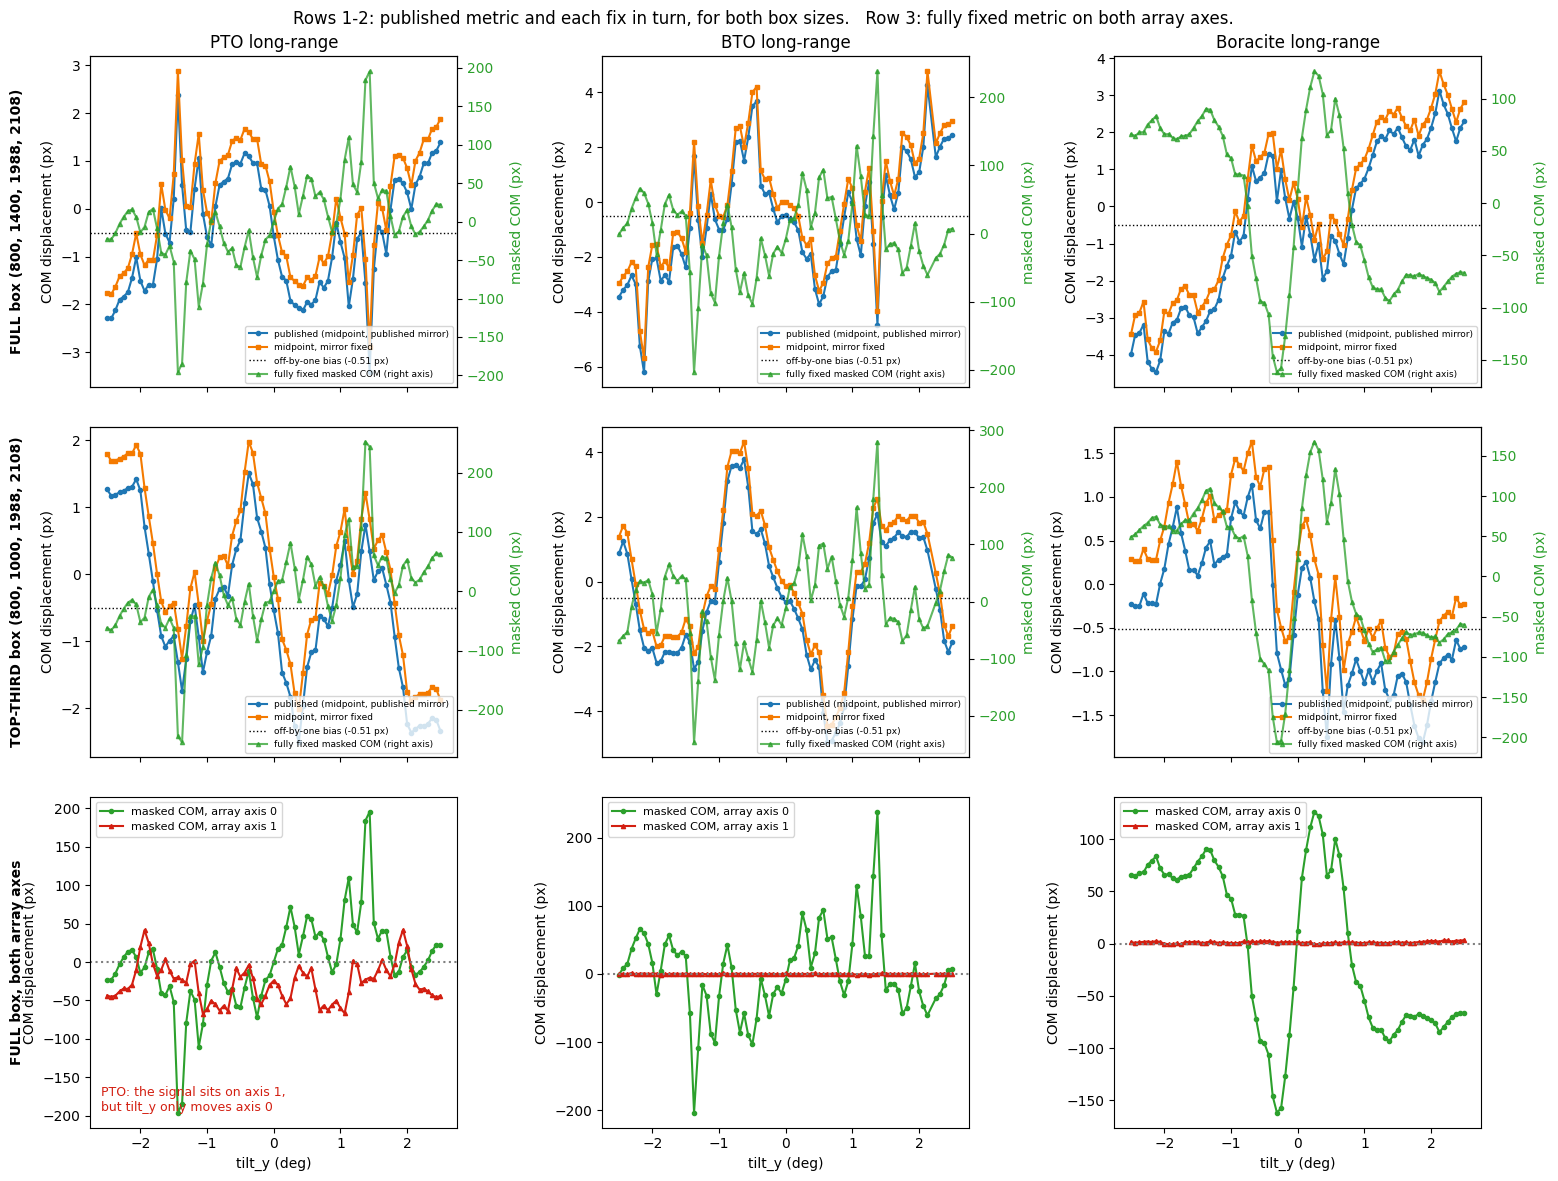

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12), sharex=True)
C_PUB, C_MIR, C_FIX, C_AX1 = "#1f77b4", "#f47a00", "#2ca02c", "#d31f11"

def triple(ax, t, pub, mir, fix, title=None):
    """Published / mirror-fixed / fully-fixed. The fixed metric is ~70x larger,
    so it gets its own scale on the right."""
    ax.plot(t, pub, "o-", ms=3, color=C_PUB, label="published (midpoint, published mirror)")
    ax.plot(t, mir, "s-", ms=3, color=C_MIR, label="midpoint, mirror fixed")
    ax.axhline(-0.511, color="k", ls=":", lw=1, label="off-by-one bias (-0.51 px)")
    ax.set_ylabel("COM displacement (px)")
    if title:
        ax.set_title(title)
    r = ax.twinx()
    r.plot(t, fix, "^-", ms=3, color=C_FIX, alpha=0.75,
           label="fully fixed masked COM (right axis)")
    r.set_ylabel("masked COM (px)", color=C_FIX)
    r.tick_params(axis="y", labelcolor=C_FIX)
    r.spines["right"].set_visible(True)
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = r.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=6.5, loc="lower right")

for k, m in enumerate(LONG):
    t, s = tilt[m], sweeps[m]
    c = lambda box, j: s[:, COL[(box, j)]]

    triple(axes[0, k], t, c("full", 0), c("full", 1), c("full", 2),
           title=f"{m} long-range")
    triple(axes[1, k], t, c("third", 0), c("third", 1), c("third", 2))

    b = axes[2, k]
    b.plot(t, c("full", 2), "o-", ms=3, color=C_FIX, label="masked COM, array axis 0")
    b.plot(t, c("full", 3), "^-", ms=3, color=C_AX1, label="masked COM, array axis 1")
    b.axhline(0, color="gray", ls=":")
    b.set_xlabel("tilt_y (deg)")
    b.set_ylabel("COM displacement (px)")
    b.legend(fontsize=8)

for r, lbl in ((0, f"FULL box {FULL_BOX}"), (1, f"TOP-THIRD box {THIRD_BOX}"),
               (2, "FULL box, both array axes")):
    axes[r, 0].text(-0.20, 0.5, lbl, transform=axes[r, 0].transAxes, fontsize=10,
                    rotation=90, va="center", ha="center", fontweight="bold")

axes[2, 0].text(0.03, 0.05,
                "PTO: the signal sits on axis 1,\nbut tilt_y only moves axis 0",
                transform=axes[2, 0].transAxes, fontsize=9, color=C_AX1)
fig.suptitle("Rows 1-2: published metric and each fix in turn, for both box sizes.   "
             "Row 3: fully fixed metric on both array axes.", fontsize=12)
fig.tight_layout(rect=[0.02, 0, 1, 1])
fig.savefig("kikuchi_com_diagnosis.png", dpi=140)
plt.show()

## Conclusions

| claim | verdict |
|---|---|
| COM should mask both boxes and take one centroid | **confirmed** — the midpoint cancels the intensity imbalance, which is the signal |
| centre point off by a pixel | **confirmed**, but in `infer_box2_from_box1`, not in `center_y`; `N/2` is correct |
| wrong polarisation direction simulated | **confirmed for PTO only** — run down `[010]`; BTO and boracite are fine |

**To redo the PTO panel**, re-run the long-range sweep with `ZONE_AXIS = [1,0,0]`. The
short-range equivalent already exists and is correctly oriented
(`INCOMPLETE_PTO_kikuchi_final_asymmetry_data.npz`), but it is thin — the polar offset in the
short-range sweeps is not significant for any material, so the effect needs the thick runs.

**Also fix in `simulation_scripts/*_kikuchi_tilt_split_sim.py`**: `adjust_boxes_for_tilt` is
called with `apply_y_shift=False, apply_x_shift=True`, which tracks the boxes along array
axis 1 while the pattern moves along axis 0. It was a no-op on the saved data (the recorded
box coordinates never move), so it did not corrupt these results, but the flags are inverted.